# eda_htl_modification — EDA สำหรับคำถาม "การดัดแปลงผิว HTL ช่วยจริงไหม ผ่านกลไกอะไร"

อ่านจาก `processed/prepared_v2/` **อย่างเดียว ไม่เขียนดิสก์**

**ทำไมต้องมีโน้ตบุ๊กนี้แยกจาก `explore_prepared_v2`**
`explore_prepared_v2` เป็น EDA แบบสำรวจทั่วไป (coverage, การกระจาย, naive correlation ของทุกคอลัมน์)
โน้ตบุ๊กนี้เจาะเฉพาะคำถามที่ข้อมูลชุดนี้**ตอบได้จริง**ใต้ LeaveOneGroupOut — เพราะการนับพบว่า
process knob เชิงตัวเลขทุกตัวคงที่ภายใน paper (แปรผัน 0/15 paper) จึง confound 100% กับตัวตนของ paper
ตัวแปรเดียวที่มี **within-paper contrast** จริงคือ *การดัดแปลงผิว HTL* (`htl_mod_kind` / `coat_htl`) — 10-11/15 paper

หน่วยวิเคราะห์จึงเปลี่ยนจาก "device" เป็น **"คู่ control vs treated ภายใน paper เดียวกัน"** = การทดลอง A/B ในแล็บเดียว
(แล็บเดียว คนเดียว เครื่องเดียว ล็อตสารเดียว) ซึ่งเป็นหลักฐานที่แข็งแรงที่สุดที่ observational data แบบนี้ให้ได้

**ลำดับ**
1. design matrix — paper ไหนตอบคำถามนี้ได้บ้าง
2. ทำไมการเทียบข้าม paper ใช้ไม่ได้ (variance + การนับ within-paper variation)
3. ผลหลัก — Δ(treated − control) ภายใน paper ทุก metric + sign test
4. mediator — VTFL ลดจริงไหม โซ่กลไกต่อกันครบไหม
5. แยกตามกลุ่มสารดัดแปลง (SAM / เกลือไอออน / ออกไซด์ / โมเลกุลอินทรีย์)
6. dose-response — 2 paper ที่ไล่ความเข้มข้น
7. audit ตัวกวน — treated/control ใน paper เดียวกันใช้สูตรเดียวกันจริงไหม
8. เสถียรภาพ (n เล็กมาก — exploratory)
9. contrast เชิงตัวเลขอันเดียวที่มีในทั้ง dataset
10. ชุดข้อมูลสำหรับ modeling + สรุป

> ทุกตัวเลขในนี้คือ **within-paper** ยกเว้นที่ระบุว่า naive/between — ไม่ใช่ผลจากโมเดล ยังไม่มี bootstrap CI

In [1]:
from math import comb
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import font_manager

ROOT = Path.cwd() if (Path.cwd() / "processed" / "prepared_v2").exists() else Path.cwd().parent
V2 = ROOT / "processed" / "prepared_v2"

tt = pd.read_csv(V2 / "target_table.csv")
layers = pd.read_csv(V2 / "layers.csv")
tt["paper"] = tt["device_id"].str.rsplit("_Sample", n=1).str[0]

# palette + สไตล์เดียวกับ explore_prepared_v2
# เลือกฟอนต์ไทยตัวแรกที่เครื่องนี้มีจริง (กัน matplotlib สาดคำเตือน findfont เต็มหน้าจอ)
_have = {f.name for f in font_manager.fontManager.ttflist}
FONT = next((f for f in ["Leelawadee UI", "Sarabun", "Thonburi", "Tahoma", "Ayuthaya", "DejaVu Sans"] if f in _have),
            "DejaVu Sans")
C1, C2, C3, C4 = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
INK, INK2, MUTED, GRID, BASE = "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
plt.rcParams.update({
    "font.family": [FONT, "DejaVu Sans"], "axes.unicode_minus": False,
    "figure.dpi": 110, "figure.facecolor": "white",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": BASE, "axes.labelcolor": INK2,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titlecolor": INK, "axes.titlesize": 11, "font.size": 9.5})


def spearman(x, y):
    """rho, n — เขียนเองเพราะ env ไม่มี scipy (rank correlation = pearson บน rank)"""
    m = pd.notna(x) & pd.notna(y)
    if m.sum() < 3:
        return np.nan, int(m.sum())
    return float(np.corrcoef(pd.Series(x)[m].rank(), pd.Series(y)[m].rank())[0, 1]), int(m.sum())


def sign_test(vals):
    """p สองด้านแบบ exact binomial (H0: P(+) = 0.5), ทิ้งค่า 0/NaN -> (p, k_pos, n)"""
    v = [x for x in vals if pd.notna(x) and x != 0]
    n, k = len(v), sum(1 for x in v if x > 0)
    if n == 0:
        return np.nan, 0, 0
    pmf = [comb(n, i) * 0.5 ** n for i in range(n + 1)]
    p = sum(q for q in pmf if q <= pmf[k] + 1e-12)
    return min(1.0, p), k, n


def short(p, n=24):
    return p if len(p) <= n else p[:n - 1] + "…"


# --- วัสดุที่ใช้ดัดแปลงผิว HTL (layer 3) ต่อ device ---
# layer_id 3 อาจมีหลายแถวต่อ device (สารผสม) -> รวมเป็นสตริงเดียว
l3 = (layers[layers.layer_id == 3]
      .groupby("device_id")["material"]
      .apply(lambda s: " + ".join(sorted(s.dropna().unique())))
      .replace("", np.nan))
tt["htl_mod_material"] = tt["device_id"].map(l3)


def mod_class(mat):
    """จัดกลุ่มสารดัดแปลงผิว HTL ตามตระกูลเคมี (จากรายชื่อจริงใน dataset)"""
    if not isinstance(mat, str) or not mat:
        return "ไม่ดัดแปลง"
    m = mat.upper()
    if any(k in m for k in ("PACZ", "PADBC", "PADMAC", "SAM")):
        return "SAM (carbazole)"
    if any(k in m for k in ("PF6", "CSI", "EMIMI")):
        return "เกลือไอออน / IL"
    if "AL2O3" in m:
        return "ออกไซด์"
    return "โมเลกุลอินทรีย์"


tt["mod_class"] = tt["htl_mod_material"].map(mod_class)
tt["treated"] = tt["htl_mod_kind"].notna()      # coating หรือ additive = ถูกดัดแปลง

# paper ที่มีทั้ง control และ treated ในตัวเอง = ตอบคำถามนี้ได้
_v = tt.groupby("paper")["treated"].nunique()
CONTRAST = sorted(_v[_v == 2].index)

print(f"devices {len(tt)} | papers {tt.paper.nunique()} | treated {int(tt.treated.sum())} / control {int((~tt.treated).sum())}")
print(f"paper ที่มี within-paper contrast (มีทั้ง control+treated): {len(CONTRAST)}/15")
print("กลุ่มสาร:", tt.mod_class.value_counts().to_dict())
print("ฟอนต์กราฟ:", FONT)

devices 44 | papers 15 | treated 29 / control 15
paper ที่มี within-paper contrast (มีทั้ง control+treated): 11/15
กลุ่มสาร: {'ไม่ดัดแปลง': 15, 'เกลือไอออน / IL': 10, 'SAM (carbazole)': 10, 'โมเลกุลอินทรีย์': 6, 'ออกไซด์': 3}
ฟอนต์กราฟ: Sarabun


## 1. Design matrix — paper ไหนตอบคำถามนี้ได้บ้าง

หลักการ: จะวัดผลของ "การดัดแปลงผิว HTL" ได้ ต้องมีคู่เทียบที่**ต่างกันแค่เรื่องนี้** = อยู่ใน paper เดียวกัน
paper ที่ทุก device ถูกดัดแปลงหมด (หรือไม่ถูกดัดแปลงเลย) ให้ contrast ไม่ได้ → ตกจากการวิเคราะห์หลัก

,n,control,treated,contrast,kind,materials
paper,,,,,,
10.1002admi.202500231,4,1,3,ใช้ได้,additive,"EMIMI-1%, EMIMI-2%, EMIMI-4%"
10.1016j.jechem.2021.11.029,2,1,1,ใช้ได้,coating,BDT-POZ
10.1021_acsami.5c16972,3,1,2,ใช้ได้,coating,"Me-4PACz, Me-4PACz + PFPTFB"
10_1002adma_202507730,5,1,4,ใช้ได้,coating,"3F-PTES, BA, F-PTES, PTES"
10_1016_j_heliyon_2024_e25352,5,1,4,ใช้ได้,coating,"CsI 10 mg/mL, CsI 15 mg/mL, CsI 20 mg/mL, CsI ..."
10_1016_j_solener_2025_113286,2,1,1,ใช้ได้,coating,2PACz SAM
10_1021_acsami_4c14300,2,1,1,ใช้ได้,coating,TFFA
10_1021_acsami_5c15868,3,1,2,ใช้ได้,coating,"Me-4PACz (SAM), Me-4PACz (SAM) + GPC"
10_1039_d3lf00258f,4,1,3,ใช้ได้,coating,"LiPF6, NH4PF6, NaPF6"


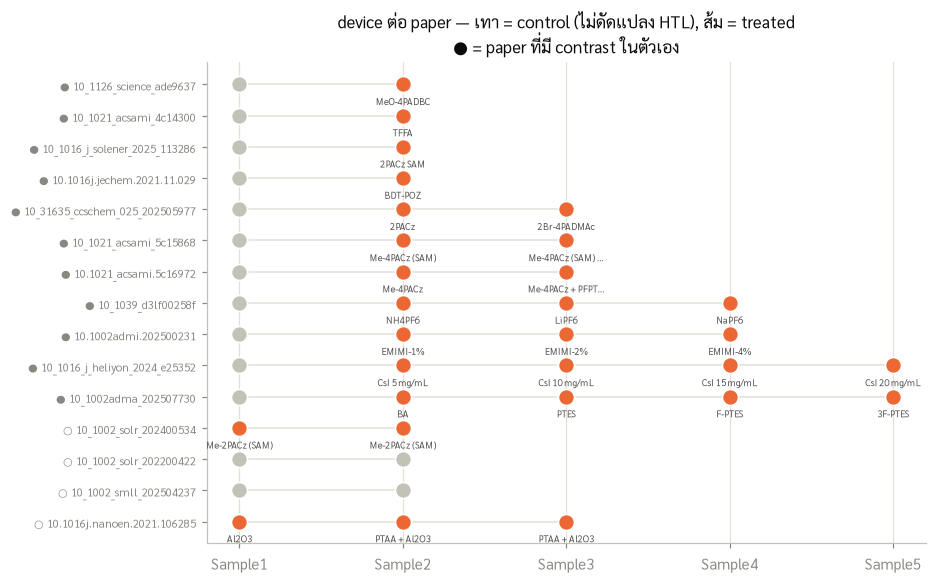

ใช้ได้ 11 paper / 35 device
ตกไป: 10.1016j.nanoen.2021.106285, 10_1002_smll_202504237, 10_1002_solr_202200422, 10_1002_solr_202400534


In [2]:
rows = []
for p, d in tt.groupby("paper"):
    ctrl, trt = (~d.treated).sum(), d.treated.sum()
    rows.append(dict(
        paper=p, n=len(d), control=int(ctrl), treated=int(trt),
        contrast="ใช้ได้" if p in CONTRAST else "—",
        kind="/".join(sorted(d.htl_mod_kind.dropna().unique())) or "—",
        materials=", ".join(sorted(d.htl_mod_material.dropna().unique())) or "—"))
design = pd.DataFrame(rows).sort_values(["contrast", "paper"], ascending=[True, True])
display(design.set_index("paper"))

fig, ax = plt.subplots(figsize=(8.6, 5.4))
order = design.sort_values(["contrast", "n"], ascending=[False, False]).paper.tolist()
for i, p in enumerate(order):
    d = tt[tt.paper == p].sort_values("treated")
    for j, (_, r) in enumerate(d.iterrows()):
        ax.scatter(j, i, s=110, zorder=3,
                   color=(C2 if r.treated else BASE),
                   edgecolor="white", linewidth=1.1)
        if isinstance(r.htl_mod_material, str):
            ax.text(j, i - 0.34, short(r.htl_mod_material, 16), ha="center", va="top",
                    fontsize=6.2, color=INK2)
    ax.plot([0, len(d) - 1], [i, i], color=GRID, lw=1, zorder=1)
ax.set_yticks(range(len(order)),
              [("● " if p in CONTRAST else "○ ") + short(p, 30) for p in order], fontsize=7.5)
ax.set_xticks(range(5), [f"Sample{i+1}" for i in range(5)])
ax.grid(axis="y", visible=False)
ax.set_title("device ต่อ paper — เทา = control (ไม่ดัดแปลง HTL), ส้ม = treated\n● = paper ที่มี contrast ในตัวเอง")
plt.tight_layout(); plt.show()

print(f"ใช้ได้ {len(CONTRAST)} paper / {int(tt[tt.paper.isin(CONTRAST)].shape[0])} device")
print("ตกไป:", ", ".join(short(p, 40) for p in design[design.contrast == "—"].paper))

## 2. ทำไมเทียบข้าม paper ไม่ได้ — และอะไรบ้างที่แปรผันภายใน paper

สองหลักฐานประกอบกัน:
1. **variance ของ Y ระหว่าง paper ใหญ่กว่าภายใน paper มาก** → ความต่างของแล็บกลบผลของตัวแปรที่สนใจ
2. **feature เชิงตัวเลขแทบไม่แปรค่าภายใน paper เลย** → ใต้ LOPO โมเดลแยกไม่ออกว่าเป็นผลของ knob หรือของ paper

การนับข้อ 2 คือเหตุผลทั้งหมดที่คำถามวิจัยต้องย้ายมาที่การดัดแปลงผิว HTL

variance ของ Y (ระหว่าง paper vs ภายใน paper):
  pce   between   10.519 | within   3.460 | ratio   3.0x  (n paper ที่คิด within ได้ = 15)
  voc   between    0.004 | within   0.001 | ratio   3.8x  (n paper ที่คิด within ได้ = 15)
  jsc   between    4.220 | within   1.089 | ratio   3.9x  (n paper ที่คิด within ได้ = 15)
  ff    between   17.431 | within   7.368 | ratio   2.4x  (n paper ที่คิด within ได้ = 15)
  vtfl  between    0.069 | within   0.021 | ratio   3.3x  (n paper ที่คิด within ได้ = 11)


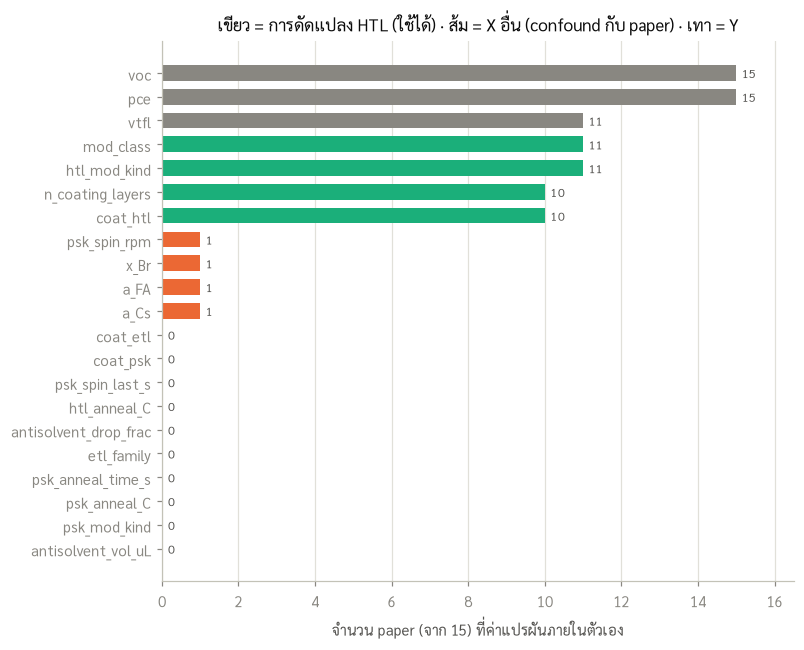

แปรผันภายใน paper 0 ครั้ง = confound 100% กับ paper identity:
   psk_anneal_C, psk_anneal_time_s, antisolvent_vol_uL, antisolvent_drop_frac, htl_anneal_C, psk_spin_last_s, coat_psk, coat_etl, etl_family, psk_mod_kind


In [3]:
# 2.1 variance ระหว่าง vs ภายใน paper
print("variance ของ Y (ระหว่าง paper vs ภายใน paper):")
for y in ["pce", "voc", "jsc", "ff", "vtfl"]:
    g = tt.dropna(subset=[y]).groupby("paper")[y]
    b = g.mean().var()                                  # variance ของค่ากลางรายเปเปอร์
    w = g.var().dropna().mean()                         # variance ภายในเปเปอร์ (เปเปอร์ที่มี >1 device)
    print(f"  {y:5s} between {b:8.3f} | within {w:7.3f} | ratio {b/w:5.1f}x  (n paper ที่คิด within ได้ = {int(g.var().notna().sum())})")

# 2.2 นับ paper ที่ค่าแปรผันภายในตัวเอง
NA_IS_LEVEL = {"htl_mod_kind", "psk_mod_kind"}   # NaN = "ไม่ดัดแปลง" เป็นระดับจริง ไม่ใช่ข้อมูลหาย
FEATS = ["htl_mod_kind", "coat_htl", "n_coating_layers", "mod_class",
         "a_Cs", "a_FA", "x_Br", "psk_spin_rpm", "psk_anneal_C", "psk_anneal_time_s",
         "antisolvent_vol_uL", "antisolvent_drop_frac", "htl_anneal_C", "psk_spin_last_s",
         "coat_psk", "coat_etl", "etl_family", "psk_mod_kind",
         "pce", "voc", "vtfl"]
var_within = pd.Series(
    {f: int((tt.groupby("paper")[f].nunique(dropna=(f not in NA_IS_LEVEL)) > 1).sum()) for f in FEATS})

fig, ax = plt.subplots(figsize=(7.4, 6))
grp = ["Y (เทียบ)" if f in ("pce", "voc", "vtfl") else
       ("HTL mod" if f in ("htl_mod_kind", "coat_htl", "n_coating_layers", "mod_class") else "X อื่น")
       for f in var_within.index]
col = {"HTL mod": C3, "Y (เทียบ)": MUTED, "X อื่น": C2}
s = var_within.sort_values()
ax.barh(s.index, s.values, color=[col[grp[list(var_within.index).index(f)]] for f in s.index], height=0.66)
for i, v in enumerate(s.values):
    ax.text(v + 0.15, i, str(v), va="center", fontsize=8, color=INK2)
ax.set_xlim(0, 16.5); ax.grid(axis="y", visible=False)
ax.set_xlabel("จำนวน paper (จาก 15) ที่ค่าแปรผันภายในตัวเอง")
ax.set_title("เขียว = การดัดแปลง HTL (ใช้ได้) · ส้ม = X อื่น (confound กับ paper) · เทา = Y")
plt.tight_layout(); plt.show()

print("แปรผันภายใน paper 0 ครั้ง = confound 100% กับ paper identity:")
print("  ", ", ".join(var_within[var_within == 0].index))

## 3. ผลหลัก — Δ(treated − control) ภายใน paper เดียวกัน

วิธีคิด: ใน paper หนึ่ง ๆ เทียบ **ค่าเฉลี่ยของ device ที่ถูกดัดแปลง** กับ **ค่าเฉลี่ยของ control ในเปเปอร์นั้น**
ได้ Δ หนึ่งค่าต่อหนึ่ง paper → paper เป็นหน่วยวิเคราะห์ (ไม่ใช่ device) จึงไม่มี pseudo-replication

รายงาน 2 แบบ:
- **Δmean** — เฉลี่ยทุก treated เทียบ control = ผลของ "การดัดแปลงโดยเฉลี่ย" (รวมโดสที่แย่ด้วย) → conservative
- **Δbest** — treated ตัวที่ดีที่สุดเทียบ control = ผลของ "การดัดแปลงที่ปรับจนดีแล้ว" → ตรงกับที่เปเปอร์เคลม

sign test = ทดสอบว่าทิศทางที่เห็นเกิดจากการสุ่มได้ไหม (ไม่ต้องสมมติการแจกแจง เหมาะกับ n เล็ก)

In [4]:
HIGHER_BETTER = {"pce": True, "voc": True, "jsc": True, "ff": True, "retention_25c": True,
                 "vtfl": False, "trap_density": False, "rs": False, "degradation_rate": False,
                 "rrec": True}


def paired_delta(metric):
    rows = []
    for p, d in tt[tt.paper.isin(CONTRAST)].groupby("paper"):
        c = d.loc[~d.treated, metric].dropna()
        t = d.loc[d.treated, metric].dropna()
        if not len(c) or not len(t):
            continue
        best = t.max() if HIGHER_BETTER[metric] else t.min()
        rows.append(dict(paper=p, n_ctrl=len(c), n_trt=len(t),
                         control=c.mean(), treated_mean=t.mean(), treated_best=best,
                         d_mean=t.mean() - c.mean(), d_best=best - c.mean()))
    return pd.DataFrame(rows)


summary = []
deltas = {}
for m in ["pce", "ff", "jsc", "voc", "vtfl", "trap_density", "rs", "retention_25c"]:
    D = paired_delta(m)
    deltas[m] = D
    if D.empty:
        continue
    good = D.d_mean > 0 if HIGHER_BETTER[m] else D.d_mean < 0
    p_val, k, n = sign_test(D.d_mean * (1 if HIGHER_BETTER[m] else -1))
    summary.append(dict(metric=m, n_paper=len(D),
                        median_d_mean=f"{D.d_mean.median():+.4g}",     # str กัน trap_density (1e15) ดัน
                        median_d_best=f"{D.d_best.median():+.4g}",     # ทั้งตารางเป็น scientific notation
                        ทิศทางดี=f"{int(good.sum())}/{len(D)}",
                        sign_test_p=round(p_val, 4)))
display(pd.DataFrame(summary).set_index("metric"))

print("อ่านว่า: ΔPCE median +2.09% และดีขึ้นทุกเปเปอร์ 11/11 — ถ้าการดัดแปลงไม่มีผลจริง")
print("โอกาสได้ทิศเดียวกันครบ 11 ตัวโดยบังเอิญ ≈ 0.1% (sign test)")

,n_paper,median_d_mean,median_d_best,ทิศทางดี,sign_test_p
metric,,,,,
pce,11,+2.09,+2.33,11/11,0.0010
ff,11,+2.62,+4.53,11/11,0.0010
jsc,11,+0.72,+0.9,11/11,0.0010
voc,11,+0.045,+0.05,9/11,0.0654
vtfl,8,-0.145,-0.175,8/8,0.0078
trap_density,7,-1.85e+15,-1.85e+15,7/7,0.0156
rs,4,-4.972,-5.255,3/4,0.6250
retention_25c,3,+25,+25,3/3,0.2500


อ่านว่า: ΔPCE median +2.09% และดีขึ้นทุกเปเปอร์ 11/11 — ถ้าการดัดแปลงไม่มีผลจริง
โอกาสได้ทิศเดียวกันครบ 11 ตัวโดยบังเอิญ ≈ 0.1% (sign test)


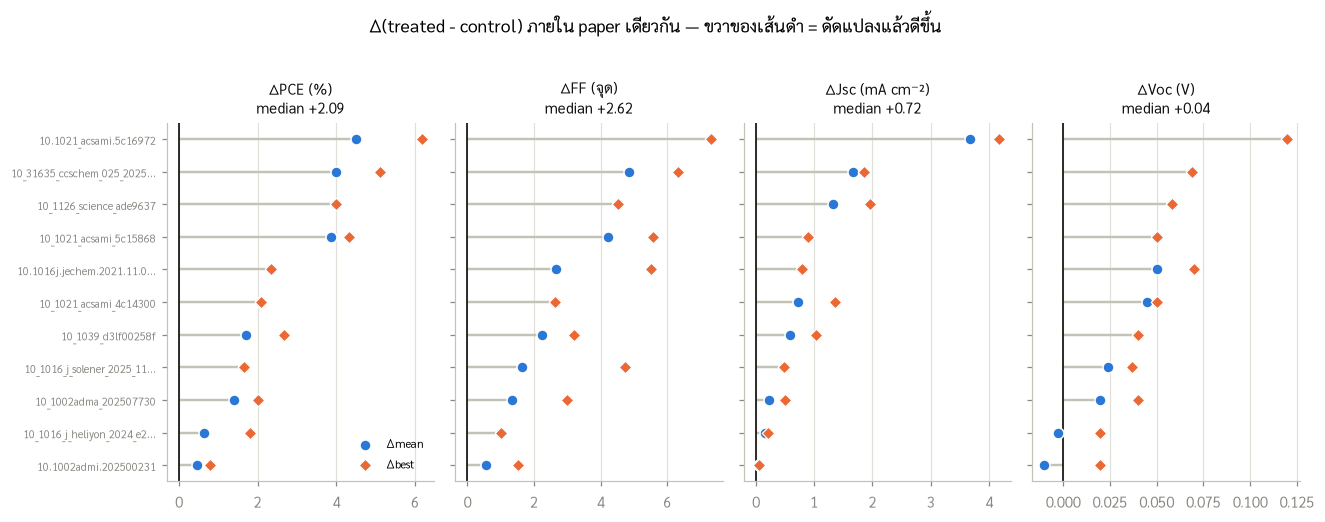

Voc เป็นตัวเดียวที่ไม่ 11/11 — เปเปอร์ที่ Voc ลด:


,control,treated_mean,d_mean,d_best
paper,,,,
10.1002admi.202500231,1.02,1.010,-0.010,0.02
10_1016_j_heliyon_2024_e25352,1.04,1.038,-0.002,0.02


(Δbest ยังบวก 11/11 = ใน 2 เปเปอร์นี้มีโดส/สารที่ดันให้ Voc ขึ้นได้ แต่เฉลี่ยรวมโดสที่แย่แล้วติดลบ)


In [5]:
fig, axes = plt.subplots(1, 4, figsize=(12, 4.6), sharey=True)
for ax, m, lab in zip(axes, ["pce", "ff", "jsc", "voc"],
                      ["ΔPCE (%)", "ΔFF (จุด)", "ΔJsc (mA cm⁻²)", "ΔVoc (V)"]):
    D = deltas[m].sort_values("d_mean")
    y = range(len(D))
    ax.axvline(0, color=INK, lw=1.1, zorder=2)
    ax.hlines(y, 0, D.d_mean, color=BASE, lw=1.6, zorder=1)
    ax.scatter(D.d_mean, y, s=52, color=C1, edgecolor="white", linewidth=1, zorder=3, label="Δmean")
    ax.scatter(D.d_best, y, s=34, color=C2, marker="D", edgecolor="white", linewidth=0.8, zorder=3, label="Δbest")
    ax.set_title(f"{lab}\nmedian {D.d_mean.median():+.2f}", fontsize=9.5)
    ax.grid(axis="y", visible=False)
axes[0].set_yticks(range(len(deltas["pce"].sort_values("d_mean"))),
                   [short(p, 26) for p in deltas["pce"].sort_values("d_mean").paper], fontsize=7)
axes[0].legend(frameon=False, fontsize=7.5, loc="lower right")
fig.suptitle("Δ(treated - control) ภายใน paper เดียวกัน — ขวาของเส้นดำ = ดัดแปลงแล้วดีขึ้น", y=1.02)
plt.tight_layout(); plt.show()

D = deltas["voc"]
neg = D[D.d_mean < 0]
print("Voc เป็นตัวเดียวที่ไม่ 11/11 — เปเปอร์ที่ Voc ลด:")
display(neg[["paper", "control", "treated_mean", "d_mean", "d_best"]].round(3).set_index("paper"))
print("(Δbest ยังบวก 11/11 = ใน 2 เปเปอร์นี้มีโดส/สารที่ดันให้ Voc ขึ้นได้ แต่เฉลี่ยรวมโดสที่แย่แล้วติดลบ)")

## 4. Mediator — VTFL ลดจริงไหม (โซ่กลไกต่อกันครบหรือยัง)

สมมุติฐานเชิงกลไก: `ดัดแปลงผิว HTL → trap ที่รอยต่อลด → FF/Voc ขึ้น → PCE ขึ้น`

`vtfl` (trap-filled limit voltage จาก SCLC) = ตัวแทนความหนาแน่น trap — **สูง = trap เยอะ = ฟิล์มแย่**
ถ้าโซ่นี้จริง ต้องเห็นสองอย่าง: (ก) VTFL ลดในเปเปอร์ที่วัด (ข) เปเปอร์ที่ VTFL ลดมาก ควรได้ PCE/FF ขึ้นมาก

ΔVTFL: median -0.145 V | ลดลง 8/8 เปเปอร์ | sign test p = 0.0078


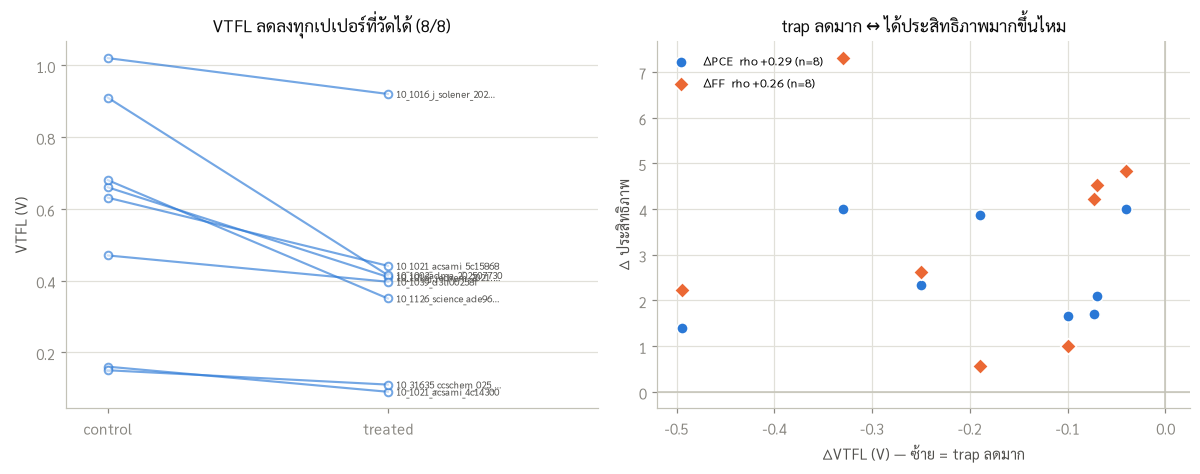

,n_ctrl,n_trt,control,treated_mean,d_mean
paper,,,,,
10.1016j.jechem.2021.11.029,1,1,0.660,0.410,-0.250
10_1002adma_202507730,1,2,0.910,0.415,-0.495
10_1016_j_solener_2025_113286,1,1,1.020,0.920,-0.100
10_1021_acsami_4c14300,1,1,0.160,0.090,-0.070
10_1021_acsami_5c15868,1,2,0.631,0.441,-0.190
10_1039_d3lf00258f,1,3,0.470,0.397,-0.073
10_1126_science_ade9637,1,1,0.680,0.350,-0.330
10_31635_ccschem_025_202505977,1,2,0.150,0.110,-0.040


⚠️ n=8 เปเปอร์ — ทิศทาง (ก) ชัดมาก แต่ความชันของ (ข) ยังประเมินไม่แม่น
   ขนาด mediation จริง (ผลผ่าน trap กี่ %) ต้องรอโมเดลเต็มที่คุม composition + LOPO


In [6]:
D = deltas["vtfl"]
p_val, k, n = sign_test(-D.d_mean)
print(f"ΔVTFL: median {D.d_mean.median():+.3f} V | ลดลง {int((D.d_mean < 0).sum())}/{len(D)} เปเปอร์ | sign test p = {p_val:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4.4))

# ซ้าย: slope chart control -> treated รายเปเปอร์
ax = axes[0]
for _, r in D.iterrows():
    ax.plot([0, 1], [r.control, r.treated_mean], color=C1, alpha=0.65, lw=1.4, marker="o", ms=5,
            markerfacecolor="white", markeredgewidth=1.3)
    ax.text(1.03, r.treated_mean, short(r.paper, 22), fontsize=6.5, va="center", color=INK2)
ax.set_xticks([0, 1], ["control", "treated"]); ax.set_xlim(-0.15, 1.75)
ax.set_ylabel("VTFL (V)"); ax.grid(axis="x", visible=False)
ax.set_title(f"VTFL ลดลงทุกเปเปอร์ที่วัดได้ ({int((D.d_mean<0).sum())}/{len(D)})")

# ขวา: ΔVTFL vs ΔPCE / ΔFF
ax = axes[1]
for m, c, mk in [("pce", C1, "o"), ("ff", C2, "D")]:
    j = D.merge(deltas[m], on="paper", suffixes=("_v", f"_{m}"))
    rho, nn = spearman(j["d_mean_v"], j[f"d_mean_{m}"])
    ax.scatter(j["d_mean_v"], j[f"d_mean_{m}"], s=54, color=c, marker=mk,
               edgecolor="white", linewidth=1, label=f"Δ{m.upper()}  rho {rho:+.2f} (n={nn})")
ax.axvline(0, color=BASE, lw=1); ax.axhline(0, color=BASE, lw=1)
ax.set_xlabel("ΔVTFL (V) — ซ้าย = trap ลดมาก"); ax.set_ylabel("Δ ประสิทธิภาพ")
ax.legend(frameon=False, fontsize=8); ax.set_title("trap ลดมาก ↔ ได้ประสิทธิภาพมากขึ้นไหม")
plt.tight_layout(); plt.show()

display(D[["paper", "n_ctrl", "n_trt", "control", "treated_mean", "d_mean"]].round(3).set_index("paper"))
print("⚠️ n=8 เปเปอร์ — ทิศทาง (ก) ชัดมาก แต่ความชันของ (ข) ยังประเมินไม่แม่น")
print("   ขนาด mediation จริง (ผลผ่าน trap กี่ %) ต้องรอโมเดลเต็มที่คุม composition + LOPO")

## 5. แยกตามกลุ่มสารที่ใช้ดัดแปลง

ทั้ง 4 กลุ่มทำงานคนละกลไกในทางเคมี:
- **SAM (carbazole)** — โมเลกุลชั้นเดียวเกาะผิว NiOx (2PACz, Me-4PACz, MeO-4PADBC …) จัดระดับพลังงาน + ปรับความเปียก
- **เกลือไอออน / IL** — CsI, NH₄PF₆, LiPF₆, NaPF₆, EMIMI: ไอออนไปเติมช่องว่าง/ปรับ dipole ที่ผิว
- **ออกไซด์** — Al₂O₃ บาง ๆ กั้นปฏิกิริยาเคมี Ni³⁺ กับ perovskite
- **โมเลกุลอินทรีย์** — BDT-POZ, PTES/F-PTES, TFFA, BA

⚠️ n ต่อกลุ่มเล็กมาก (1-4 paper) — ดูทิศทางได้ ยังจัดอันดับไม่ได้ ต้องรอ SHAP ที่คุมสูตรเคมี

,n_paper,n_device,median_dPCE,median_dPCE_best
mod_class,,,,
SAM (carbazole),5,8,4.00,4.33
เกลือไอออน / IL,3,10,0.65,1.80
โมเลกุลอินทรีย์,3,5,2.09,2.09


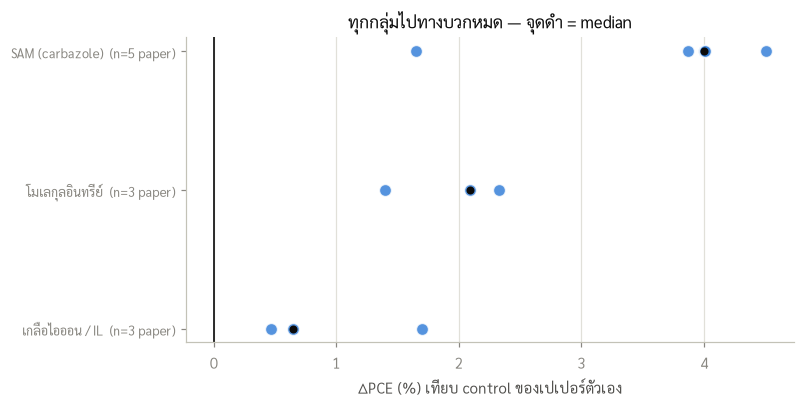

กลุ่มที่หลุดจากตารางนี้: ['ออกไซด์']
  (ออกไซด์ = Al2O3 มีเปเปอร์เดียว `nanoen.2021.106285` ซึ่งทุก device ถูกเคลือบหมด ไม่มี control
   จึงคำนวณ Δ ไม่ได้ — ไม่ใช่ว่าไม่มีข้อมูล แต่ออกแบบการทดลองไม่มีคู่เทียบ)


In [7]:
rows = []
for p, d in tt[tt.paper.isin(CONTRAST)].groupby("paper"):
    c = d.loc[~d.treated, "pce"].dropna()
    if not len(c):
        continue
    for cls, g in d[d.treated].groupby("mod_class"):
        v = g["pce"].dropna()
        if len(v):
            rows.append(dict(paper=p, mod_class=cls, n_dev=len(v),
                             d_mean=v.mean() - c.mean(), d_best=v.max() - c.mean()))
bycls = pd.DataFrame(rows)

display(bycls.groupby("mod_class").agg(
    n_paper=("paper", "nunique"), n_device=("n_dev", "sum"),
    median_dPCE=("d_mean", "median"), median_dPCE_best=("d_best", "median")).round(2))

fig, ax = plt.subplots(figsize=(7.4, 3.8))
order = bycls.groupby("mod_class")["d_mean"].median().sort_values().index
for i, cls in enumerate(order):
    v = bycls[bycls.mod_class == cls]
    ax.scatter(v.d_mean, [i] * len(v), s=64, color=C1, alpha=0.8, edgecolor="white", linewidth=1, zorder=3)
    ax.scatter(v.d_mean.median(), i, s=18, color=INK, zorder=4)
ax.axvline(0, color=INK, lw=1.1)
ax.set_yticks(range(len(order)), [f"{c}  (n={bycls[bycls.mod_class==c].paper.nunique()} paper)" for c in order], fontsize=8.5)
ax.grid(axis="y", visible=False); ax.set_xlabel("ΔPCE (%) เทียบ control ของเปเปอร์ตัวเอง")
ax.set_title("ทุกกลุ่มไปทางบวกหมด — จุดดำ = median")
plt.tight_layout(); plt.show()

missing = sorted(set(tt.loc[tt.treated, "mod_class"]) - set(bycls.mod_class))
print("กลุ่มที่หลุดจากตารางนี้:", missing or "— ไม่มี —")
print("  (ออกไซด์ = Al2O3 มีเปเปอร์เดียว `nanoen.2021.106285` ซึ่งทุก device ถูกเคลือบหมด ไม่มี control")
print("   จึงคำนวณ Δ ไม่ได้ — ไม่ใช่ว่าไม่มีข้อมูล แต่ออกแบบการทดลองไม่มีคู่เทียบ)")

## 6. Dose-response — 2 เปเปอร์ที่ไล่ความเข้มข้น

นี่คือที่เดียวที่ข้อมูลบอกเรื่อง "ปริมาณ" ได้ เพราะทั้งสองไล่โดสภายในแล็บเดียวกัน:
- `heliyon_2024_e25352` — CsI 5 / 10 / 15 / 20 mg mL⁻¹
- `admi.202500231` — EMIMI 1 / 2 / 4 % (แบบ additive ผสมในน้ำหมึก NiOx ไม่ใช่เคลือบทับ)

ประเด็นที่ต้องดู: ผลเป็นเส้นตรงหรือมี**จุดเหมาะสม** — ถ้ามีจุดเหมาะสม การสรุปด้วย "treated เฉลี่ย" จะกลบข้อมูลสำคัญทิ้ง

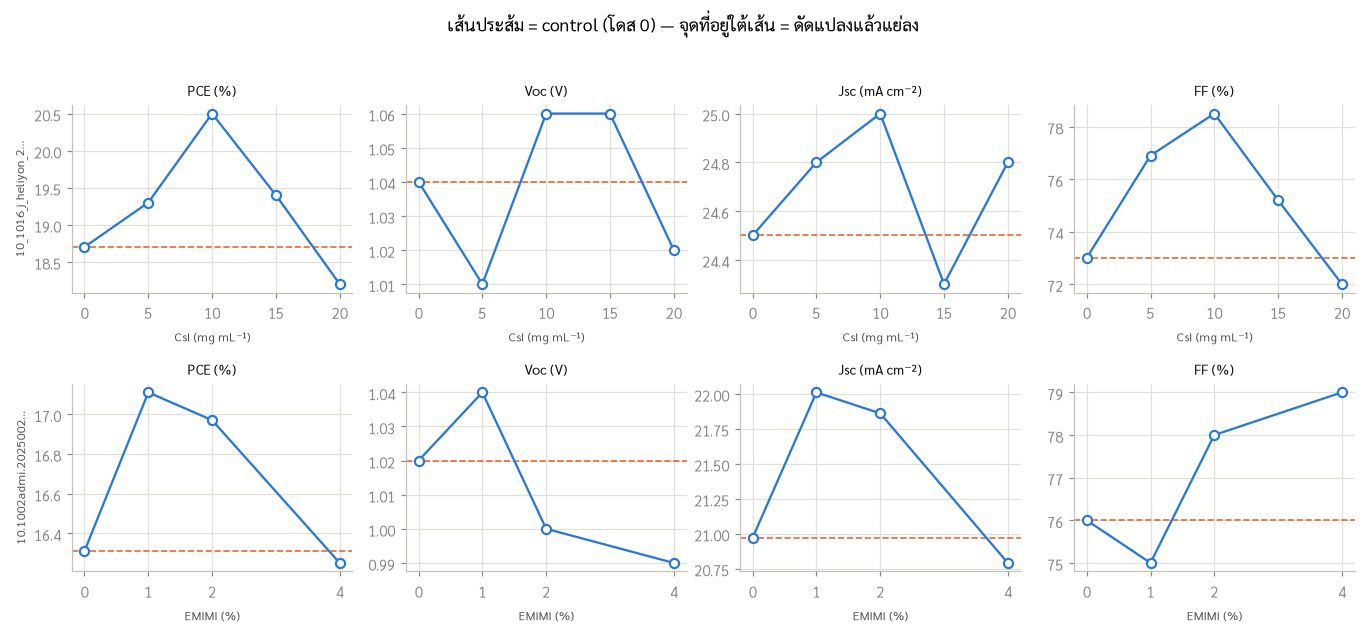

10_1016_j_heliyon_2024_e25352      control 18.70 | ดีสุดที่โดส   10 = 20.50 (+1.80) | แย่สุดที่โดส   20 = 18.20 (-0.50)
10.1002admi.202500231              control 16.31 | ดีสุดที่โดส    1 = 17.11 (+0.80) | แย่สุดที่โดส    4 = 16.25 (-0.06)

→ ทั้งสองเปเปอร์เป็นเส้นโค้งคว่ำ (มีจุดเหมาะสม) ไม่ใช่ 'ยิ่งมากยิ่งดี'
  ใส่มากเกินแย่กว่าไม่ใส่เลย — เหตุผลที่ต้องรายงาน Δbest คู่กับ Δmean เสมอ


In [8]:
SERIES = {"10_1016_j_heliyon_2024_e25352": ("CsI (mg mL⁻¹)", {"Sample1": 0, "Sample2": 5, "Sample3": 10, "Sample4": 15, "Sample5": 20}),
          "10.1002admi.202500231": ("EMIMI (%)", {"Sample1": 0, "Sample2": 1, "Sample3": 2, "Sample4": 4})}

fig, axes = plt.subplots(2, 4, figsize=(12.5, 5.6))
for r, (p, (xlab, dose)) in enumerate(SERIES.items()):
    d = tt[tt.paper == p].copy()
    d["dose"] = d.device_id.str.rsplit("_", n=1).str[-1].map(dose)
    d = d.sort_values("dose")
    for ax, m, lab in zip(axes[r], ["pce", "voc", "jsc", "ff"],
                          ["PCE (%)", "Voc (V)", "Jsc (mA cm⁻²)", "FF (%)"]):
        ax.plot(d.dose, d[m], color=C1, lw=1.5, marker="o", ms=6,
                markerfacecolor="white", markeredgewidth=1.4, zorder=3)
        base = d.loc[d.dose == 0, m]
        if len(base):
            ax.axhline(base.iloc[0], color=C2, lw=1.1, ls="--", zorder=2)
        ax.set_xlabel(xlab, fontsize=8); ax.set_title(lab, fontsize=9)
        ax.set_xticks(sorted(d.dose))
    axes[r][0].set_ylabel(short(p, 20), fontsize=8)
fig.suptitle("เส้นประส้ม = control (โดส 0) — จุดที่อยู่ใต้เส้น = ดัดแปลงแล้วแย่ลง", y=1.02)
plt.tight_layout(); plt.show()

for p, (xlab, dose) in SERIES.items():
    d = tt[tt.paper == p].copy()
    d["dose"] = d.device_id.str.rsplit("_", n=1).str[-1].map(dose)
    best = d.loc[d.pce.idxmax()]
    ctrl = d.loc[d.dose == 0, "pce"].iloc[0]
    worst = d[d.dose > 0].loc[d[d.dose > 0].pce.idxmin()]
    print(f"{short(p, 32):34s} control {ctrl:5.2f} | ดีสุดที่โดส {best.dose:>4} = {best.pce:5.2f} ({best.pce-ctrl:+.2f}) "
          f"| แย่สุดที่โดส {worst.dose:>4} = {worst.pce:5.2f} ({worst.pce-ctrl:+.2f})")
print("\n→ ทั้งสองเปเปอร์เป็นเส้นโค้งคว่ำ (มีจุดเหมาะสม) ไม่ใช่ 'ยิ่งมากยิ่งดี'")
print("  ใส่มากเกินแย่กว่าไม่ใส่เลย — เหตุผลที่ต้องรายงาน Δbest คู่กับ Δmean เสมอ")

## 7. Audit ตัวกวน — treated กับ control ใน paper เดียวกันใช้สูตรเดียวกันจริงไหม

Δ ในข้อ 3 จะสะอาดก็ต่อเมื่อ **ภายในเปเปอร์เดียวกัน ทุกอย่างนอกจากการดัดแปลง HTL เหมือนกันหมด**
เช็คทีละเปเปอร์ว่ามีอะไรแปรร่วมไปด้วยหรือเปล่า (composition, ETL, knob การผลิต, ชนิดค่า JV ที่รายงาน)

In [9]:
CHECK = ["a_Cs", "a_FA", "x_Br", "etl_family", "coat_psk", "psk_spin_rpm", "psk_anneal_C",
         "psk_anneal_time_s", "antisolvent_vol_uL", "antisolvent_drop_frac", "htl_anneal_C", "jv_variant"]
flags = []
for p in CONTRAST:
    d = tt[tt.paper == p]
    for c in CHECK:
        if d[c].nunique(dropna=True) > 1:
            flags.append(dict(paper=p, column=c, values=sorted(d[c].dropna().unique().tolist())))
fl = pd.DataFrame(flags)
if fl.empty:
    print("✅ ไม่มีเปเปอร์ contrast ไหนที่ตัวแปรอื่นแปรร่วมเลย — Δ สะอาดทุกตัว")
else:
    display(fl.set_index(["paper", "column"]))
print()
print("เทียบ: เปเปอร์ที่ไม่ได้อยู่ในชุด contrast แต่มีค่าแปรภายใน (ไว้ดูว่ามีอะไรตกหล่นไหม)")
oth = []
for p in [x for x in tt.paper.unique() if x not in CONTRAST]:
    d = tt[tt.paper == p]
    for c in CHECK:
        if d[c].nunique(dropna=True) > 1:
            oth.append(dict(paper=p, column=c, values=sorted(d[c].dropna().unique().tolist())))
display(pd.DataFrame(oth).set_index(["paper", "column"]) if oth else "— ไม่มี —")

✅ ไม่มีเปเปอร์ contrast ไหนที่ตัวแปรอื่นแปรร่วมเลย — Δ สะอาดทุกตัว

เทียบ: เปเปอร์ที่ไม่ได้อยู่ในชุด contrast แต่มีค่าแปรภายใน (ไว้ดูว่ามีอะไรตกหล่นไหม)


values
paper                       column                        
10.1016j.nanoen.2021.106285 a_Cs               [0.0, 0.04]
                            a_FA             [0.83, 0.838]
                            x_Br               [0.1, 0.12]
10_1002_solr_202400534      psk_spin_rpm  [1000.0, 5000.0]

## 8. เสถียรภาพ — สัญญาณเดียวกันไหม (n เล็กมาก, exploratory เท่านั้น)

`retention_25c` มีแค่ 14 device และเหลือแค่ 3 เปเปอร์ที่มีทั้ง control และ treated
ดูได้แค่ว่า "ทิศทางขัดกับฝั่งประสิทธิภาพหรือเปล่า" — สรุปเชิงปริมาณไม่ได้

หมายเหตุที่ต้องจำ: การดัดแปลงบางแบบ (เช่น 2D layer จาก PEAI ฝั่ง PSK) **เสื่อมเร็วช่วงแรก**
retention ที่ดีขึ้นในกลุ่มดัดแปลง HTL จึงไม่ควรเหมารวมเป็นข้อสรุปของ passivation ทุกชนิด


retention_25c: 3 เปเปอร์มีคู่เทียบ (จาก 14 device ทั้ง dataset)


,n_ctrl,n_trt,control,treated_mean,d_mean
paper,,,,,
10.1021_acsami.5c16972,1,2,43.00,81.0,38.00
10_1016_j_solener_2025_113286,1,1,55.00,80.0,25.00
10_1021_acsami_5c15868,1,1,68.96,87.7,18.74



degradation_rate: 3 เปเปอร์มีคู่เทียบ (จาก 14 device ทั้ง dataset)


,n_ctrl,n_trt,control,treated_mean,d_mean
paper,,,,,
10.1021_acsami.5c16972,1,2,0.041,0.014,-0.027
10_1016_j_solener_2025_113286,1,1,0.045,0.020,-0.025
10_1021_acsami_5c15868,1,1,0.028,0.011,-0.017


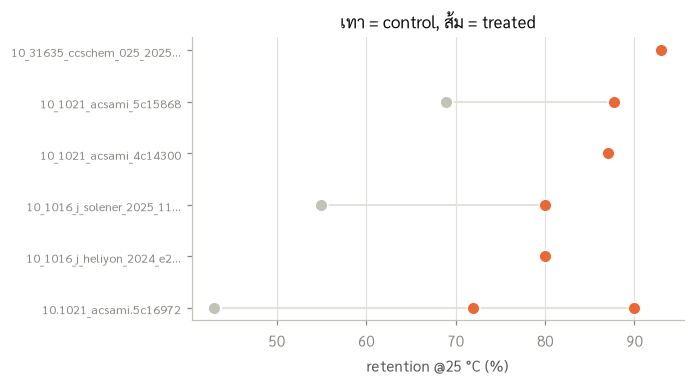

⚠️ 3 เปเปอร์ — ใช้เป็นข้อสังเกตประกอบเท่านั้น ห้ามรายงานเป็นผลหลัก


In [10]:
for m in ["retention_25c", "degradation_rate"]:
    D = deltas.get(m)
    if D is None:
        D = paired_delta(m)
    print(f"\n{m}: {len(D)} เปเปอร์มีคู่เทียบ (จาก {int(tt[m].notna().sum())} device ทั้ง dataset)")
    if len(D):
        display(D[["paper", "n_ctrl", "n_trt", "control", "treated_mean", "d_mean"]].round(3).set_index("paper"))

st = tt[tt.paper.isin(CONTRAST)].dropna(subset=["retention_25c"])
fig, ax = plt.subplots(figsize=(6.4, 3.6))
for i, (p, d) in enumerate(st.groupby("paper")):
    for _, r in d.iterrows():
        ax.scatter(r.retention_25c, i, s=70, color=(C2 if r.treated else BASE),
                   edgecolor="white", linewidth=1.1, zorder=3)
    ax.plot([d.retention_25c.min(), d.retention_25c.max()], [i, i], color=GRID, lw=1.2, zorder=1)
ax.set_yticks(range(st.paper.nunique()), [short(p, 26) for p in sorted(st.paper.unique())], fontsize=8)
ax.grid(axis="y", visible=False); ax.set_xlabel("retention @25 °C (%)")
ax.set_title("เทา = control, ส้ม = treated")
plt.tight_layout(); plt.show()
print("⚠️ 3 เปเปอร์ — ใช้เป็นข้อสังเกตประกอบเท่านั้น ห้ามรายงานเป็นผลหลัก")

## 9. contrast เชิงตัวเลขอันเดียวที่มีอยู่ในทั้ง dataset

จากข้อ 2: knob ตัวเลขแปรผันภายในเปเปอร์ 0 ครั้ง — **ยกเว้นตัวเดียว** คือ `psk_spin_rpm`
ใน `10_1002_solr_202400534` (2 device, SAM เหมือนกันทั้งคู่, ต่างกันแค่ความเร็ว spin)

เก็บไว้เป็นหลักฐานประกอบว่า knob ตัวเลข *น่าจะ* มีผลจริงถ้าเก็บข้อมูลมาให้ถูกแบบ — แต่ n=1 เปเปอร์ สรุปอะไรไม่ได้
และเป็นตัวอย่างรูปธรรมของ "เปเปอร์แบบที่ต้องเก็บเพิ่ม" ถ้าจะกลับไปตอบคำถามเดิม (ทาง 2)

In [11]:
solo = tt[tt.paper == "10_1002_solr_202400534"][
    ["device_id", "htl_mod_material", "psk_spin_rpm", "pce", "voc", "jsc", "ff", "vtfl", "retention_25c"]]
display(solo.set_index("device_id").round(3))
a, b = solo.sort_values("psk_spin_rpm").iloc[0], solo.sort_values("psk_spin_rpm").iloc[-1]
print(f"spin {b.psk_spin_rpm:.0f} → {a.psk_spin_rpm:.0f} rpm : PCE {b.pce:.2f} → {a.pce:.2f} ({a.pce-b.pce:+.2f}), "
      f"VTFL {b.vtfl:.2f} → {a.vtfl:.2f} ({a.vtfl-b.vtfl:+.2f})")
print("(สารดัดแปลง HTL เหมือนกันทั้งคู่ = Me-2PACz → ความต่างมาจาก spin จริง แต่ n=2 device)")

,htl_mod_material,psk_spin_rpm,pce,voc,jsc,ff,vtfl,retention_25c
device_id,,,,,,,,
10_1002_solr_202400534_Sample1,Me-2PACz (SAM),5000.0,20.37,1.147,22.24,80.3,0.74,90.31
10_1002_solr_202400534_Sample2,Me-2PACz (SAM),1000.0,24.21,1.155,25.96,80.4,0.68,100.85


spin 5000 → 1000 rpm : PCE 20.37 → 24.21 (+3.84), VTFL 0.74 → 0.68 (-0.06)
(สารดัดแปลง HTL เหมือนกันทั้งคู่ = Me-2PACz → ความต่างมาจาก spin จริง แต่ n=2 device)


## 10. ชุดข้อมูลสำหรับ modeling + สรุป

ประกอบ frame ที่ขั้น RF+SHAP จะใช้จริง แล้วเช็คสามอย่างก่อนส่งต่อ:
1. feature ที่ variance = 0 (ใช้ไม่ได้)
2. feature ที่ไม่มี within-paper variation (ใส่ได้แต่ SHAP จะอ่านเป็น paper fingerprint)
3. ขนาด fold ของ LOPO (fold ที่มี device เดียวประเมิน metric รายกลุ่มไม่ได้)

In [12]:
X_MAIN = ["htl_mod_kind", "coat_htl", "mod_class"]                   # ตัวแปรหลัก (มี within-paper contrast)
X_CTRL = ["a_Cs", "a_FA", "x_Br", "etl_family"]                      # ตัวควบคุม (confounder เชิงเคมี/สถาปัตยกรรม)
MED = ["vtfl", "trap_density", "rs", "rrec"]
Y = ["voc", "jsc", "ff", "pce", "retention_25c"]

mdl = tt[["device_id", "paper"] + X_MAIN + X_CTRL + MED + Y].copy()
print("coverage (จาก 44 device):")
print(mdl.drop(columns=["device_id", "paper"]).notna().sum().to_string())

print("\n⚠️ variance 0 ทั้ง dataset (ใช้เป็น feature ไม่ได้):")
zero = [c for c in X_MAIN + X_CTRL if mdl[c].nunique(dropna=False) <= 1]
print("  ", zero or "— ไม่มี —")

print("\n⚠️ ไม่มี within-paper variation (ใส่เป็นตัวควบคุมได้ แต่ห้ามอ่าน SHAP เป็นเชิงกลไก):")
print("  ", [c for c in X_CTRL if (tt.groupby("paper")[c].nunique(dropna=True) > 1).sum() == 0])

fold = tt.groupby("paper").size().sort_values()
print(f"\nLOPO: {len(fold)} fold | ขนาด {fold.min()}-{fold.max()} device | fold ที่มี ≤2 device: {int((fold<=2).sum())}")
print("→ รายงานผลรวมแบบ pooled prediction ข้าม fold ไม่ใช่ค่าเฉลี่ยของ R² รายกลุ่ม (fold เล็กเกินไป)")
display(mdl.head(8))

coverage (จาก 44 device):
htl_mod_kind     29
coat_htl         44
mod_class        44
a_Cs             44
a_FA             44
x_Br             44
etl_family       44
vtfl             28
trap_density     22
rs               22
rrec             15
voc              43
jsc              43
ff               43
pce              42
retention_25c    14

⚠️ variance 0 ทั้ง dataset (ใช้เป็น feature ไม่ได้):
   — ไม่มี —

⚠️ ไม่มี within-paper variation (ใส่เป็นตัวควบคุมได้ แต่ห้ามอ่าน SHAP เป็นเชิงกลไก):
   ['etl_family']

LOPO: 15 fold | ขนาด 2-5 device | fold ที่มี ≤2 device: 7
→ รายงานผลรวมแบบ pooled prediction ข้าม fold ไม่ใช่ค่าเฉลี่ยของ R² รายกลุ่ม (fold เล็กเกินไป)


,device_id,paper,htl_mod_kind,coat_htl,mod_class,a_Cs,a_FA,x_Br,etl_family,vtfl,trap_density,rs,rrec,voc,jsc,ff,pce,retention_25c
0,10.1002admi.202500231_Sample1,10.1002admi.202500231,NaN,False,ไม่ดัดแปลง,0.05,0.790,0.13,C60,NaN,NaN,0.68,NaN,1.020,20.97,76.00,16.31,NaN
1,10.1002admi.202500231_Sample2,10.1002admi.202500231,additive,False,เกลือไอออน / IL,0.05,0.790,0.13,C60,NaN,NaN,0.64,NaN,1.040,22.01,75.00,17.11,NaN
2,10.1002admi.202500231_Sample3,10.1002admi.202500231,additive,False,เกลือไอออน / IL,0.05,0.790,0.13,C60,NaN,NaN,0.62,NaN,1.000,21.86,78.00,16.97,NaN
3,10.1002admi.202500231_Sample4,10.1002admi.202500231,additive,False,เกลือไอออน / IL,0.05,0.790,0.13,C60,NaN,NaN,0.53,NaN,0.990,20.79,79.00,16.25,NaN
4,10.1016j.jechem.2021.11.029_Sample1,10.1016j.jechem.2021.11.029,NaN,False,ไม่ดัดแปลง,0.05,0.807,0.15,PCBM,0.66,6.080000e+15,NaN,NaN,1.064,21.32,79.47,17.83,NaN
5,10.1016j.jechem.2021.11.029_Sample2,10.1016j.jechem.2021.11.029,coating,True,โมเลกุลอินทรีย์,0.05,0.807,0.15,PCBM,0.41,3.780000e+15,NaN,NaN,1.122,22.12,82.09,20.16,NaN
6,10.1016j.nanoen.2021.106285_Sample1,10.1016j.nanoen.2021.106285,coating,True,ออกไซด์,0.00,0.830,0.10,PCBM,0.25,3.550000e+15,29.70,14563.62,1.062,22.92,74.89,NaN,NaN
7,10.1016j.nanoen.2021.106285_Sample2,10.1016j.nanoen.2021.106285,coating,True,ออกไซด์,0.04,0.838,0.12,PCBM,0.11,2.095000e+15,20.98,39161.17,1.104,23.95,76.69,20.28,NaN


## สรุป — อ่านอะไรจากโน้ตบุ๊กนี้ได้บ้าง

**ตอบได้ (มีหลักฐาน within-paper)**
1. การดัดแปลงผิว HTL ให้ผลบวก **11/11 เปเปอร์** (ΔPCE median +2.09%, sign test p ≈ 0.001) — เป็นการเทียบ A/B ในแล็บเดียวกัน ไม่ใช่ correlation ข้ามแล็บ
2. โซ่กลไกครบทุกข้อต่อ: **VTFL ลด 8/8 เปเปอร์ที่วัด** → trap ลดจริง → FF ขึ้น 11/11 → PCE ขึ้น
3. FF เป็นทางหลักที่ผลวิ่งผ่าน (Δ +2.62 จุด, 11/11) มากกว่า Voc (9/11 ตอนเฉลี่ย) — สอดคล้องกับกลไก contact/รอยต่อ มากกว่ากลไก bulk
4. **มีจุดเหมาะสมของโดส** — 2 เปเปอร์ที่ไล่ความเข้มข้นเป็นเส้นโค้งคว่ำทั้งคู่ และโดสสูงสุดแย่กว่าไม่ใส่เลย

**ตอบไม่ได้ (และต้องประกาศให้ชัดทุกครั้ง)**
1. **ค่าตัวเลขที่ดีที่สุดของ knob ใด ๆ** — RPM/อุณหภูมิ/เวลา/antisolvent แปรผันภายในเปเปอร์ 0/15 → confound 100% กับตัวตนของแล็บ (ข้อ 2) correlation แรง ๆ ที่เคยเห็น เช่น `htl_anneal_C ~ ff` −0.74 เป็น between-paper ล้วน
2. **จัดอันดับกลุ่มสาร** — ทุกกลุ่มบวกหมด แต่ 1-4 เปเปอร์ต่อกลุ่ม แยกไม่ออกว่าใครดีกว่าใคร
3. **ข้อสรุปเรื่องเสถียรภาพ** — เหลือ 3 เปเปอร์ที่มีคู่เทียบ
4. **publication bias** — เปเปอร์ตีพิมพ์เฉพาะการดัดแปลงที่สำเร็จ 11/11 จึงต้องอ่านว่า *"การดัดแปลงที่ผ่านการคัดของแต่ละแล็บแล้ว ให้ผลขนาดนี้"* ไม่ใช่ *"ดัดแปลงอะไรก็ได้แล้วจะดีขึ้น"* — ข้อ 6 (โดสสูงแย่กว่า control) เป็นหลักฐานตรงว่าการดัดแปลงแบบไม่ปรับจูนทำให้แย่ลงได้จริง

**ขั้นต่อไป**
- RandomForest + SHAP, LeaveOneGroupOut(paper) 15 fold — เทรน `voc`/`jsc`/`ff` แยกแล้วคูณเป็น `pce`
- คุม `a_Cs a_FA x_Br` + `etl_family` เสมอ, bootstrap CI ของ Δ ระดับเปเปอร์
- วัดขนาด mediation ผ่าน VTFL (ผลตรง vs ผลผ่าน trap) — ตัวนี้คือของใหม่ที่เปเปอร์เดี่ยวทำไม่ได้
- ผลทั้งหมด = **hypothesis สำหรับ wet-lab validation** ไม่ใช่ข้อสรุปเชิงสาเหตุ